# Support Vector Machine (SVM) Classification

This notebook trains and evaluates an SVM classifier for the existing `burnout_risk_level` labels. It follows the project's nine-feature contract and uses the same stratified split and cross-validation approach as the other model notebooks. The labels are dataset outputs, not a diagnosis or a validated real-world burnout measure.

## Required imports

We use pandas to work with the dataset, scikit-learn for splitting, scaling, SVM, and evaluation, matplotlib/seaborn for the confusion-matrix plot, and joblib to save and reload the final pipeline.

In [1]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## Project root and dataset path

The project root is the folder containing `data/` and `models/`. Checking the current folder and its parent lets this notebook work whether Jupyter starts in the repository root or in `notebooks/`.

In [2]:
dataset_relative_path = Path('data') / 'processed' / 'cognivault_cleaned_dataset.csv'
possible_project_roots = [Path.cwd(), Path.cwd().parent]
project_root = next(
    (path for path in possible_project_roots if (path / dataset_relative_path).exists()),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        f'Could not find {dataset_relative_path} from the current folder: {Path.cwd()}'
    )

data_path = project_root / dataset_relative_path
print(f'Project folder: {project_root}')
print(f'Cleaned dataset: {data_path}')

Project folder: d:\Cognivault
Cleaned dataset: d:\Cognivault\data\processed\cognivault_cleaned_dataset.csv


## Load the cleaned dataset

We read the already-prepared CSV. This notebook does not change or rewrite the dataset.

In [3]:
df = pd.read_csv(data_path)
print(f'Loaded {len(df)} rows and {len(df.columns)} columns.')
df.head(3)

Loaded 1900 rows and 16 columns.


,institution,degree,year,branch,living_arrangement,study_hours_outside_classes_per_day,academic_tasks_per_week,academic_workload,time_pressure,avg_sleep_hours,wakes_up_tired,physical_activity_days_per_week,difficulty_concentrating,academic_emotional_exhaustion,burnout_risk_score,burnout_risk_level
0,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,8,4,4,5.2,5,2,3,4,57.1,High
1,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,9,4,3,6.0,4,1,3,3,59.7,High
2,IIIT Pune,B.Tech,1,Cyber Security,Hostel,3.5,7,3,3,6.7,2,2,2,1,28.4,Low


## Validate the required columns and input features

The classifier must receive exactly the nine agreed features, in order. The numeric score and profile/context columns are not model inputs. These checks stop the notebook early if a required column is missing, a feature has missing data, or an unexpected class label appears.

In [4]:
features = [
    'study_hours_outside_classes_per_day',
    'academic_tasks_per_week',
    'academic_workload',
    'time_pressure',
    'avg_sleep_hours',
    'wakes_up_tired',
    'physical_activity_days_per_week',
    'difficulty_concentrating',
    'academic_emotional_exhaustion',
]
target = 'burnout_risk_level'
score_target = 'burnout_risk_score'
class_labels = ['Low', 'Moderate', 'High', 'Critical']
profile_context_columns = [
    'institution',
    'degree',
    'year',
    'branch',
    'living_arrangement',
    'student_id',
    'data_source',
]

required_columns = features + [target]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f'Missing required dataset columns: {missing_columns}')
if len(features) != 9 or len(set(features)) != 9:
    raise ValueError('The classifier must use exactly nine unique input features.')
if target in features or score_target in features:
    raise ValueError('Target columns must not be included in model inputs.')
leaked_profile_columns = [column for column in profile_context_columns if column in features]
if leaked_profile_columns:
    raise ValueError(f'Profile/context columns entered model inputs: {leaked_profile_columns}')
if df[features].isna().any().any():
    raise ValueError('Missing values were found in the selected input features.')

unexpected_labels = sorted(set(df[target].dropna()) - set(class_labels))
if unexpected_labels:
    raise ValueError(f'Unexpected values in {target}: {unexpected_labels}')

print(f'Validated {len(features)} input features in the required order.')
print(f'Prediction target: {target}')
print('Class counts in the cleaned dataset:')
print(df[target].value_counts().reindex(class_labels, fill_value=0).to_string())

Validated 9 input features in the required order.
Prediction target: burnout_risk_level
Class counts in the cleaned dataset:
burnout_risk_level
Low         455
Moderate    687
High        553
Critical    205


## Select the inputs and target

`X` contains only the nine input features. `y` contains the target labels the classifier learns to predict. The score and student profile information remain outside `X`.

In [5]:
X = df.loc[:, features].copy()
y = df[target].copy()

print(f'Feature matrix shape: {X.shape}')
print(f'Target vector shape: {y.shape}')
print(f'Input columns: {list(X.columns)}')

Feature matrix shape: (1900, 9)
Target vector shape: (1900,)
Input columns: ['study_hours_outside_classes_per_day', 'academic_tasks_per_week', 'academic_workload', 'time_pressure', 'avg_sleep_hours', 'wakes_up_tired', 'physical_activity_days_per_week', 'difficulty_concentrating', 'academic_emotional_exhaustion']


## Stratified 80/20 train-test split

We set aside 20% of the rows for a final test. **Stratified** means that the split keeps the four risk categories in roughly the same proportions as in the full dataset. The fixed seed `42` makes the split repeatable. We keep the test rows out of cross-validation and training.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print(f'Training set: {len(X_train)} rows ({len(X_train) / len(X):.0%})')
print(f'Test set:     {len(X_test)} rows ({len(X_test) / len(X):.0%})')
print('Training class counts:')
print(y_train.value_counts().reindex(class_labels, fill_value=0).to_string())
print('Test class counts:')
print(y_test.value_counts().reindex(class_labels, fill_value=0).to_string())

Training set: 1520 rows (80%)
Test set:     380 rows (20%)
Training class counts:
burnout_risk_level
Low         364
Moderate    550
High        442
Critical    164
Test class counts:
burnout_risk_level
Low          91
Moderate    137
High        111
Critical     41


## How SVM and scaling work

A Support Vector Machine (SVM) looks for boundaries that separate classes; this notebook uses an RBF kernel, which can represent curved boundaries. SVM is sensitive to feature scales: for example, hours and 1–5 ratings have different numeric ranges. `StandardScaler` puts each feature on a comparable scale. Keeping the scaler and SVM together in one pipeline means the scaler learns its averages and spreads from each training fold only, preventing validation or test data from leaking into preprocessing.

We use fixed settings (`C=1.0`, `gamma='scale'`, and `class_weight='balanced'`) rather than tuning against the held-out test set. Class weighting gives less frequent classes more weight during fitting. The seed is set to `42`; with the default `probability=False`, SVC does not use that seed for probability estimation.

## Stratified 5-fold cross-validation on training data

Five-fold cross-validation splits the training data into five parts. Each fold trains on four parts and validates on the fifth, rotating the validation part so every training row is checked once. Stratification preserves class proportions in each fold. We report macro F1 and High/Critical recall for every fold, plus their mean and standard deviation. The held-out test set is not used here.

In [7]:
cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_macro_f1_scores = []
cv_high_recall_scores = []
cv_critical_recall_scores = []

for fold_number, (train_indices, validation_indices) in enumerate(
    cross_validator.split(X_train, y_train),
    start=1,
):
    X_fold_train = X_train.iloc[train_indices]
    y_fold_train = y_train.iloc[train_indices]
    X_fold_validation = X_train.iloc[validation_indices]
    y_fold_validation = y_train.iloc[validation_indices]

    fold_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(
            kernel='rbf',
            C=1.0,
            gamma='scale',
            class_weight='balanced',
            random_state=42,
        )),
    ])
    fold_pipeline.fit(X_fold_train, y_fold_train)
    fold_predictions = fold_pipeline.predict(X_fold_validation)

    fold_macro_f1 = f1_score(
        y_fold_validation,
        fold_predictions,
        labels=class_labels,
        average='macro',
        zero_division=0,
    )
    fold_high_recall = recall_score(
        y_fold_validation,
        fold_predictions,
        labels=['High'],
        average=None,
        zero_division=0,
    )[0]
    fold_critical_recall = recall_score(
        y_fold_validation,
        fold_predictions,
        labels=['Critical'],
        average=None,
        zero_division=0,
    )[0]

    cv_macro_f1_scores.append(fold_macro_f1)
    cv_high_recall_scores.append(fold_high_recall)
    cv_critical_recall_scores.append(fold_critical_recall)
    print(
        f'Fold {fold_number}: macro F1 = {fold_macro_f1:.4f}, '
        f'High recall = {fold_high_recall:.4f}, '
        f'Critical recall = {fold_critical_recall:.4f}'
    )

print('\\nCross-validation mean (standard deviation):')
print(f'Macro F1:        {pd.Series(cv_macro_f1_scores).mean():.4f} ({pd.Series(cv_macro_f1_scores).std(ddof=0):.4f})')
print(f'High recall:     {pd.Series(cv_high_recall_scores).mean():.4f} ({pd.Series(cv_high_recall_scores).std(ddof=0):.4f})')
print(f'Critical recall: {pd.Series(cv_critical_recall_scores).mean():.4f} ({pd.Series(cv_critical_recall_scores).std(ddof=0):.4f})')

Fold 1: macro F1 = 0.8842, High recall = 0.8539, Critical recall = 0.9375
Fold 2: macro F1 = 0.8287, High recall = 0.7640, Critical recall = 0.9394
Fold 3: macro F1 = 0.8346, High recall = 0.7386, Critical recall = 0.9091
Fold 4: macro F1 = 0.8840, High recall = 0.8182, Critical recall = 0.9394
Fold 5: macro F1 = 0.8552, High recall = 0.7841, Critical recall = 0.9394
\nCross-validation mean (standard deviation):
Macro F1:        0.8574 (0.0236)
High recall:     0.7918 (0.0405)
Critical recall: 0.9330 (0.0120)


## Train the final SVM pipeline

After cross-validation, we fit a fresh scaler-and-SVM pipeline on the complete training split. The test set remains untouched until the next section. These model settings are the same as the settings used in each cross-validation fold.

In [8]:
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        class_weight='balanced',
        random_state=42,
    )),
])
final_pipeline.fit(X_train, y_train)
print('Final SVM pipeline fitted on the training split.')

Final SVM pipeline fitted on the training split.


## Evaluate once on the held-out test set

Accuracy is the fraction of all test records classified correctly. Precision asks how often predictions for a class were correct; recall asks how many real records of that class were found. F1 combines precision and recall. Macro F1 averages the four class F1 scores equally, so each risk level contributes the same amount. Support is the number of true test examples in each class. High and Critical recall are shown separately because missing a record in either class may be important to review.

In [9]:
# The test set is used only now, after cross-validation and final training.
test_predictions = final_pipeline.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    labels=class_labels,
    average='macro',
    zero_division=0,
)
test_report = classification_report(
    y_test,
    test_predictions,
    labels=class_labels,
    target_names=class_labels,
    output_dict=True,
    zero_division=0,
)
per_class_metrics = pd.DataFrame(test_report).T.loc[
    class_labels,
    ['precision', 'recall', 'f1-score', 'support'],
]

print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test macro F1: {test_macro_f1:.4f}')
print('\\nPer-class precision, recall, F1, and support:')
print(per_class_metrics.to_string(float_format=lambda value: f'{value:.4f}'))
print(f"\\nTest High recall:     {test_report['High']['recall']:.4f}")
print(f"Test Critical recall: {test_report['Critical']['recall']:.4f}")

Test accuracy: 0.8368
Test macro F1: 0.8425
\nPer-class precision, recall, F1, and support:
          precision  recall  f1-score  support
Low          0.9239  0.9341    0.9290  91.0000
Moderate     0.8346  0.8102    0.8222 137.0000
High         0.7925  0.7568    0.7742 111.0000
Critical     0.7755  0.9268    0.8444  41.0000
\nTest High recall:     0.7568
Test Critical recall: 0.9268


## Confusion matrix

A confusion matrix compares the true test labels with the model's predictions. Rows are the actual classes and columns are the predicted classes. Counts on the diagonal are correct predictions; other cells show which classes were confused.

Confusion matrix counts (rows = actual, columns = predicted):
Predicted  Low  Moderate  High  Critical
Actual                                  
Low         85         6     0         0
Moderate     7       111    19         0
High         0        16    84        11
Critical     0         0     3        38


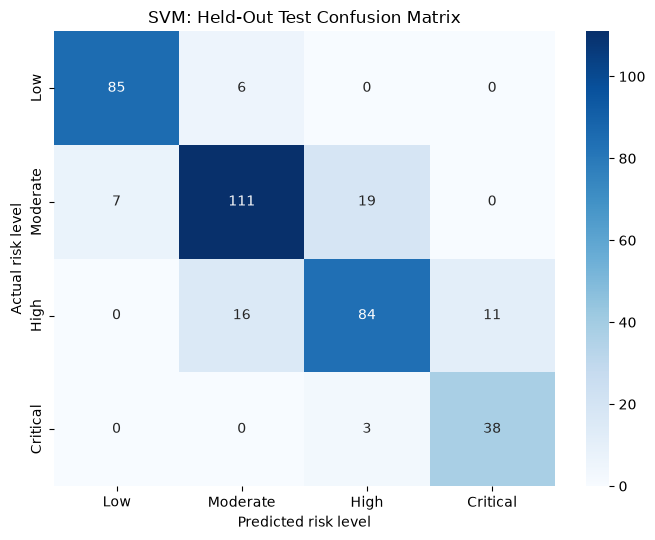

In [10]:
confusion_counts = confusion_matrix(
    y_test,
    test_predictions,
    labels=class_labels,
)
confusion_table = pd.DataFrame(
    confusion_counts,
    index=pd.Index(class_labels, name='Actual'),
    columns=pd.Index(class_labels, name='Predicted'),
)
print('Confusion matrix counts (rows = actual, columns = predicted):')
print(confusion_table.to_string())

plt.figure(figsize=(7, 5.5))
sns.heatmap(confusion_table, annot=True, fmt='d', cmap='Blues')
plt.title('SVM: Held-Out Test Confusion Matrix')
plt.xlabel('Predicted risk level')
plt.ylabel('Actual risk level')
plt.tight_layout()
plt.show()

## Feature-related analysis

This notebook uses an RBF-kernel SVM, which can form non-linear boundaries. Unlike a linear model, it does not provide a simple coefficient for each input feature, so we do not present coefficient-based feature importance as if it were meaningful.

## Save and reload the SVM pipeline

We save the complete pipeline so prediction inputs are scaled in the same way as training data. The filename is distinct from the existing Logistic Regression and Random Forest artifacts. The code stops rather than overwriting an SVM artifact that may already exist.

In [11]:
models_directory = project_root / 'models'
models_directory.mkdir(parents=True, exist_ok=True)
model_path = models_directory / 'svm_model.joblib'

if model_path.exists():
    raise FileExistsError(
        f'SVM model already exists and will not be overwritten: {model_path}'
    )

joblib.dump(final_pipeline, model_path)
print(f'Saved SVM pipeline to: {model_path}')

reloaded_pipeline = joblib.load(model_path)
if list(reloaded_pipeline.feature_names_in_) != features:
    raise ValueError('Reloaded model feature names/order do not match the nine input features.')

sample_features = X_test.iloc[[0]]
sample_prediction = reloaded_pipeline.predict(sample_features)[0]
print(f'Reloaded pipeline prediction for one held-out example: {sample_prediction}')
print('Saved-model reload and prediction check passed.')

Saved SVM pipeline to: d:\Cognivault\models\svm_model.joblib
Reloaded pipeline prediction for one held-out example: High
Saved-model reload and prediction check passed.


## Results and main findings

The cells above print the actual cross-validation and held-out test results when this notebook is run. Review macro F1 together with High and Critical recall and the confusion matrix rather than relying on accuracy alone. These results describe how well this model predicts the dataset's existing labels. They do not, by themselves, establish real-world or clinical burnout detection.

In [12]:
print('SVM results summary')
print(f'Cross-validation macro F1: {pd.Series(cv_macro_f1_scores).mean():.4f} mean')
print(f'Cross-validation High recall: {pd.Series(cv_high_recall_scores).mean():.4f} mean')
print(f'Cross-validation Critical recall: {pd.Series(cv_critical_recall_scores).mean():.4f} mean')
print(f'Held-out test accuracy: {test_accuracy:.4f}')
print(f'Held-out test macro F1: {test_macro_f1:.4f}')
print(f'Held-out test High recall: {test_report["High"]["recall"]:.4f}')
print(f'Held-out test Critical recall: {test_report["Critical"]["recall"]:.4f}')
print('Interpretation is limited to predicting the existing dataset labels; it is not a clinical validation.')

SVM results summary
Cross-validation macro F1: 0.8574 mean
Cross-validation High recall: 0.7918 mean
Cross-validation Critical recall: 0.9330 mean
Held-out test accuracy: 0.8368
Held-out test macro F1: 0.8425
Held-out test High recall: 0.7568
Held-out test Critical recall: 0.9268
Interpretation is limited to predicting the existing dataset labels; it is not a clinical validation.
